<div style="width:100%; background-color:#181818; color:#f1f1f1; padding:30px 0; text-align:center; border-radius:10px;">
  <img src="https://media3.giphy.com/media/v1.Y2lkPTc5MGI3NjExeGZqamQ3dWQ2YWM4aW50OHZjdzRpN29sdWVhbnByYndpYzIyZW5jayZlcD12MV9pbnRlcm5hbF9naWZfYnlfaWQmY3Q9Zw/xT3i1ei3Ui7rpgrsyc/giphy.gif" alt="Reinforced concrete design animation" width="400" style="max-width:100%; border-radius:10px;">
  <h3 style="color:#ffffff; margin:0 0 8px 0;"><b>Column, Interaction Diagram</b></h3>
  <p style="margin:4px 0;"><b>Authors:</b> Msc. Ing. Carlos Andr&eacute;s Celi S&aacute;nchez &middot; Nicol&aacute;s Mora Bowen &middot; Juan Sebasti&aacute;n Baquero</p>
  <p style="margin:4px 0;"><b>Course:</b> Reinforced Concrete Design II</p>
</div>

### Libraries

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Data

In [6]:
Pu = 100*1e3
Mu = 400*1e5 

h = 50
b = 30
fc = 280
fy = 4200
Es = 2000000
ecu = 0.003
beta1 = 0.85

dd = np.array([6.10, 25, 43.90])
dvar = np.array([3.2,3.2,3.2])
numvar = np.array([6,6,6])

### Calculation

In [7]:
ety = fy / Es
bwit = 0.85*fc

asi = np.pi * dvar**(2) / 4 * numvar 
Ag = b*h
Ast = np.sum(asi)
ratio  = Ast / Ag

yr = h/2
brp = np.abs(yr - dd)

cond = 0.1*Ag*fc

#--- Po,M---#
Po = 0.85*(fc*(Ag - Ast)) + fy*Ast
Pno = 0.8*(Po)
Mno = 0
fiPo = 0.65*Po
fiMno = 0.65*Mno

#--- Balance Point---#
cb = ecu / (ecu + ety) * dd[-1]
a_cb = beta1*cb
es_cb = np.abs(ecu*(dd-cb)/cb)
es_cb = np.where(es_cb > ety, ety, es_cb)
fs_cb = Es*es_cb
Cs_cb = asi * (np.where(dd <= cb, fs_cb, -fs_cb) - np.where(dd <= a_cb, bwit, 0))
Cc_cb = 0.85*fc*a_cb*b
Pn_cb = Cc_cb + np.sum(Cs_cb)
Mn_cb = Cc_cb * (yr - a_cb / 2) + np.sum(Cs_cb * (yr - dd))


if ratio >= 0.01:

    PN = []
    MN = []

    FIPN = []
    FIMN = []

    for cc in np.arange(h*1.1,0,-0.1):
        c = cc
        a = beta1*c

        #--Stress and Strain Steel--#
        esi = []
        fsi = []
        for i in np.arange(0,len(dd),1):
            esi.append(np.abs(ecu*(dd[i]-c)/c))
            if esi[i] <= ety:
                fsi.append(Es*esi[i])
            else:
                fsi.append(fy)

        #--Internal Forces / Steel--#
        Csi = []
        for i in np.arange(0,len(dd),1):
            if dd[i] <= a:
                Csi.append(asi[i]*(fsi[i] - bwit))
            else:
                Csi.append(asi[i]*fsi[i] * -1)
        Cc = bwit*a*b

        Pn = Cc + np.sum(Csi)

        #--Moments--#
        Mn = Cc*(yr - a/2) + np.sum(Csi * (yr - dd))

        #----Reduction factor----#
        aux = 0.1*fc*Ag
        if c >= cb:
            if Pn >= Pno:
                fi = 0.65
                fiPn = fi * Pno
                fiMn = fi * Mno
            else:
                fi = 0.65
                fiPn = fi * Pn
                fiMn = fi * Mn
        else:
            if aux <= Pn <= Pn_cb: 
                fi = 0.9 - (0.9 - 0.65) * (Pn - aux) / (Pn_cb - aux)
                fiPn = fi * Pn
                fiMn = fi * Mn
            else:
                fi = 0.90
                fiPn = fi * Pn
                fiMn = fi * Mn
        

        PN.append(Pn / 1000)
        MN.append(Mn / 1e5)

        FIPN.append(fiPn / 1000)
        FIMN.append(fiMn / 1e5)

        # print('='*120)
        # print('.'*90)
        # print('Geometry')
        # print(f'b = {b:.2f} cm , h = {h:.2f} cm')
        # print(f'Plastic Centroid = {yr:.2f} cm')
        # print(f'Neutral Axis = {c:.2f} cm')
        # print(f'a = {a:.2f} cm')
        # print(f'ds = {dd} cm')
        # print('.'*90)
        # print('Areas Materials')
        # print(f'As_i = {asi} cm2')
        # print(f'Ag = {Ag:.2f} cm2')
        # print('.'*90)
        # print('Strain Materials')
        # print(f'ety = {ety:.6f}')
        # print(f'es_i = {esi}')
        # print('.'*90)
        # print('Stess Materials')
        # print(f'fs_i = {fsi} kg/cm2')
        # print(f'0.85fc = {bwit:.2f} kg/cm2')
        # print('.'*90)
        # print('Force Materials')
        # print(f'Cs_i = {Csi} kg')
        # print(f'Cc = {Cc} kg')

        # print('.'*90)
        # print('Internal Capacity')
        # print(f'Pn = {Pn / 1000:.2f} T')
        # print(f'Mn = {Mn / 1e5:.2f} T-m')
        # print('='*120)

    # print(PN)
    # print(MN)
else:
    mensaje = {'error'}

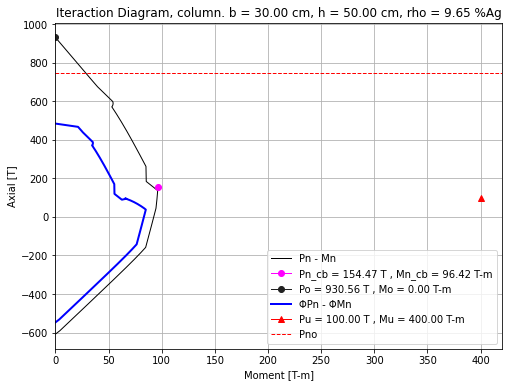

In [8]:
PNN = np.insert(PN,0,Po/1000)
MNN = np.insert(MN,0,Mno/1e5)

FIPNN = np.insert(FIPN,0,0.8*fiPo/1000)
FIMNN = np.insert(FIMN,0,0.8*fiMno/1e5)

fig, ax = plt.subplots(1,1, figsize = (8,6))
ax.plot(MNN,PNN, ls = '-', lw = 1, color = [0,0,0], label = 'Pn - Mn')

ax.plot(Mn_cb/1e5, Pn_cb/1000, ls = '-', lw = 1,marker = 'o', color = [1,0,1], 
        label = f'Pn_cb = {Pn_cb/1000:.2f} T , Mn_cb = {Mn_cb/1e5:.2f} T-m')

ax.plot(0, Po/1000, ls = '-', lw = 1,marker = 'o', color = [0.13,0.13,0.13], 
        label = f'Po = {Po/1000:.2f} T , Mo = {0:.2f} T-m')

ax.plot(FIMNN,FIPNN, ls = '-', lw = 2, color = [0,0,1], label = 'ΦPn - ΦMn')

ax.plot(Mu/1e5, Pu/1e3, ls = '-', lw = 1,marker = '^', color = [1,0,0], 
        label = f'Pu = {Pu/1000:.2f} T , Mu = {Mu/1e5:.2f} T-m')

ax.axhline(Pno/1000, ls = '--', lw = 1, color = [1,0,0], label = 'Pno')
ax.set_title(f'Iteraction Diagram, column. b = {b:.2f} cm, h = {h:.2f} cm, rho = {ratio*100:.2f} %Ag')
ax.set_xlabel('Moment [T-m]')
ax.set_ylabel('Axial [T]')
ax.set_xlim(0)
ax.grid()
ax.legend()

In [9]:
PN_df = pd.DataFrame(PNN)
PN_df

,0
0,930.557304
1,718.368712
2,717.101154
3,715.831186
4,714.558792
...,...
546,-604.976776
547,-605.583676
548,-606.190576
549,-606.797476
